In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

In [2]:
mnist = keras.datasets.mnist

In [3]:
(train_features, train_labels),(test_features, test_labels) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [4]:
train_features.shape ,test_features.shape

((60000, 28, 28), (10000, 28, 28))

8


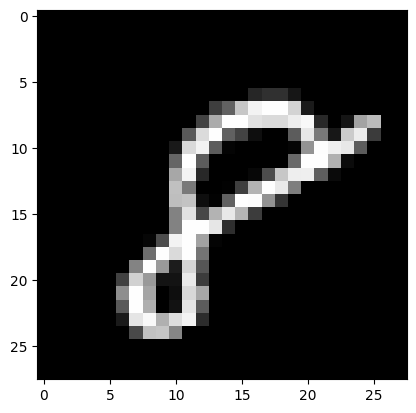

In [5]:
idx=59999
img = train_features[idx]
print(train_labels[idx])

plt.gray()
plt.imshow(img)

#preprocessing


In [6]:
np.min(img),np.max(img)

(np.uint8(0), np.uint8(255))

In [7]:
train_features = train_features/255.0
test_features= test_features/255.0

# model definition

In [8]:
model = keras . Sequential()
model.add(keras.layers.Flatten())
model.add(keras.layers.Dense(units=128 , activation='relu'))
model.add(keras.layers.Dense(units=128 , activation='relu'))
model.add(keras.layers.Dense(units=10 , activation='softmax'))

In [9]:
model.compile(optimizer=tf.optimizers.Adam() , loss = tf.losses.sparse_categorical_crossentropy, metrics=['accuracy'])

In [23]:
model.build(input_shape=(-1,784))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 354,848 (1.35 MB)

 Trainable params: 118,282 (462.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 236,566 (924.09 KB)

In [24]:
hist=model.fit(train_features , train_labels , epochs=100 , batch_size=256 ,validation_data=(test_features , test_labels))

Epoch 1/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 5.0570e-06 - val_accuracy: 0.9814 - val_loss: 0.1395
Epoch 2/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 4.4969e-06 - val_accuracy: 0.9813 - val_loss: 0.1409
Epoch 3/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 4.0983e-06 - val_accuracy: 0.9814 - val_loss: 0.1418
Epoch 4/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 3.6843e-06 - val_accuracy: 0.9813 - val_loss: 0.1440
Epoch 5/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 3.3244e-06 - val_accuracy: 0.9814 - val_loss: 0.1433
Epoch 6/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 2.9978e-06 - val_accuracy: 0.9816 - val_loss: 0.1447
Epoch 7/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 2.7070e-06 - val_accuracy: 0.9818 - val_loss: 0.1469
Epoch 8/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.00

In [25]:
model.evaluate(test_features,test_labels)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9804 - loss: 0.2214


[0.22135107219219208, 0.980400025844574]

In [26]:
idx=100
img= test_features[idx]
print(test_labels[idx])

6


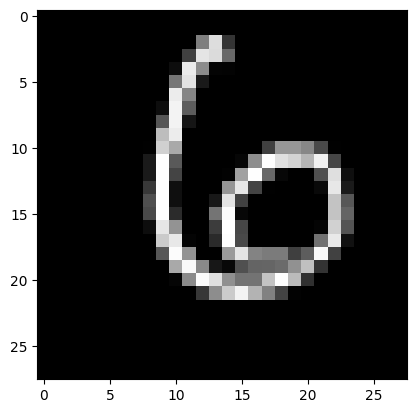

In [27]:
plt.gray()
plt.imshow(img)

In [34]:
test_data=np.reshape(img,(1,28,28))


In [35]:
model.predict(test_data)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


array([[3.2424998e-25, 3.0337199e-25, 4.1038812e-24, 6.1657132e-44,
        8.3706618e-30, 3.8806418e-27, 1.0000000e+00, 5.0842051e-40,
        4.0354291e-27, 8.4077908e-45]], dtype=float32)

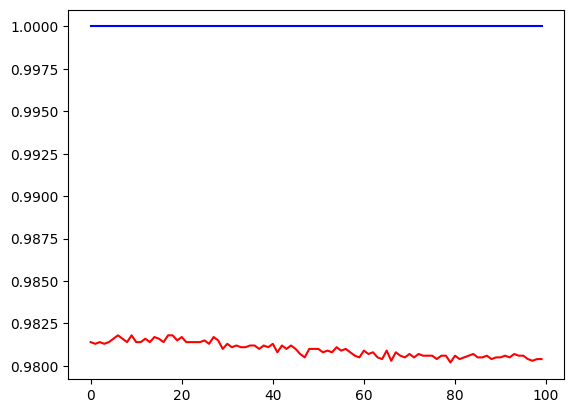

In [36]:
acc = hist. history['accuracy']
val_acc= hist.history['val_accuracy']

plt . plot (acc , color='blue')
plt.plot(val_acc, color ='red')